# Diabetes Health Indicators — Macierz Korelacji

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE = Path(__file__).parent if '__file__' in dir() else Path().resolve()
df = pd.read_csv(BASE / 'diabetes_012_health_indicators_BRFSS2015.csv')

print(df.shape)
df.head()

(253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


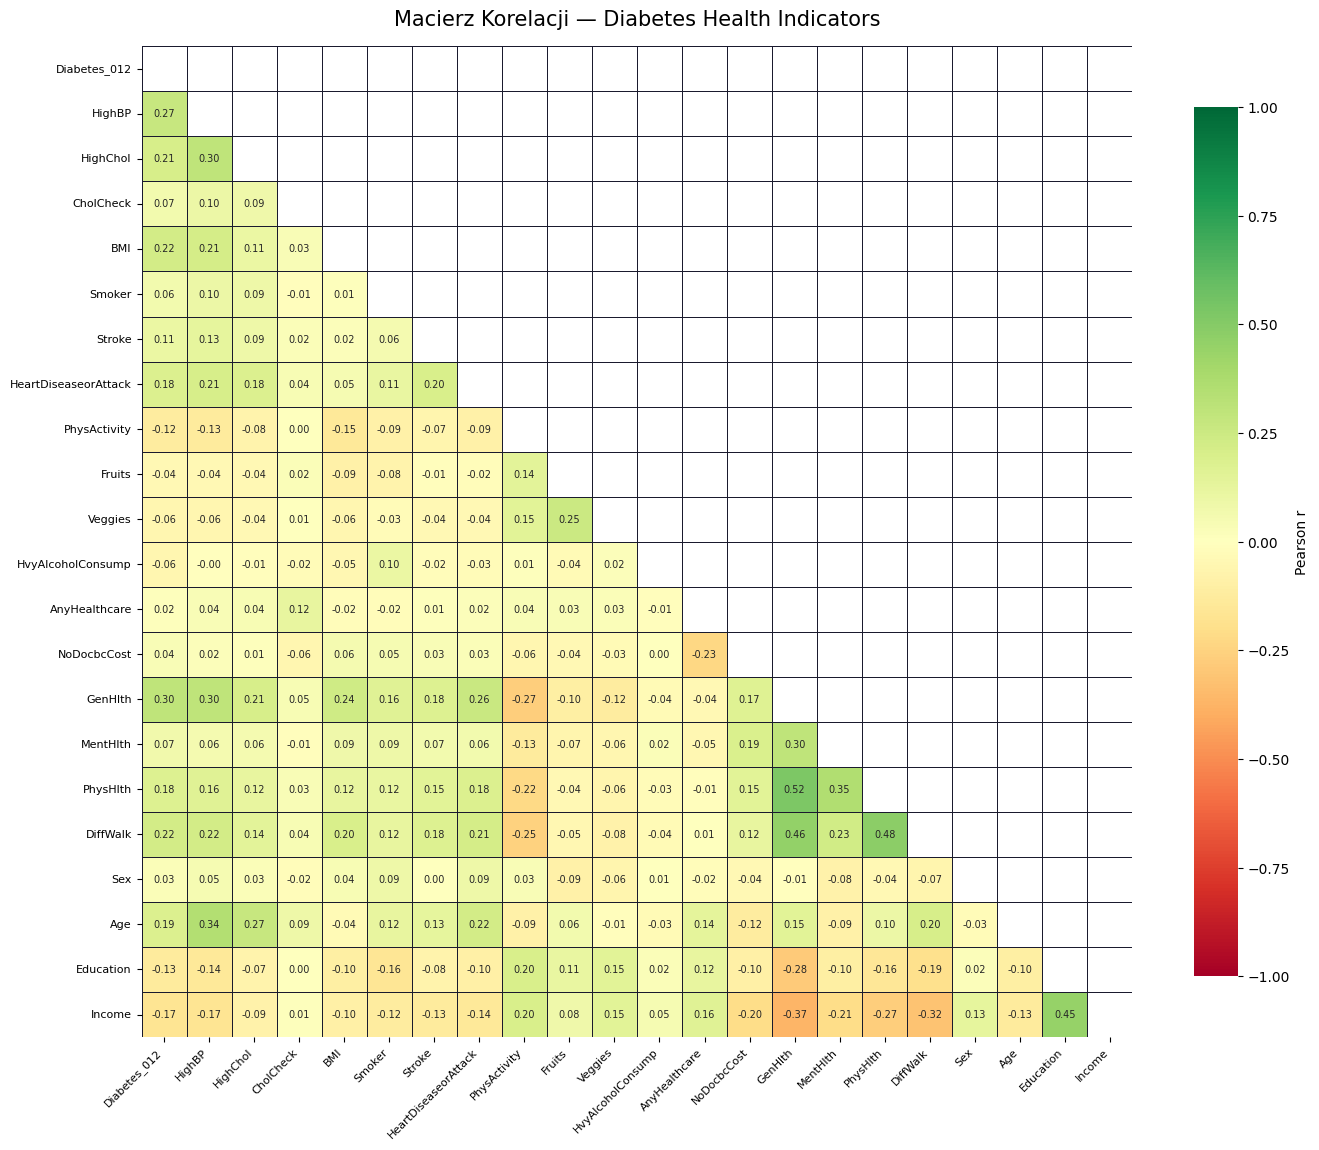

In [4]:
# --- Macierz korelacji Pearsona ---
corr = df.corr(method='pearson')

fig, ax = plt.subplots(figsize=(14, 12))

mask = np.triu(np.ones_like(corr, dtype=bool))  # tylko dolny trójkąt

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.4,
    linecolor='#1a1a2e',
    square=True,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson r'},
    annot_kws={'size': 7},
    ax=ax
)

ax.set_title('Macierz Korelacji — Diabetes Health Indicators', fontsize=15, pad=15)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

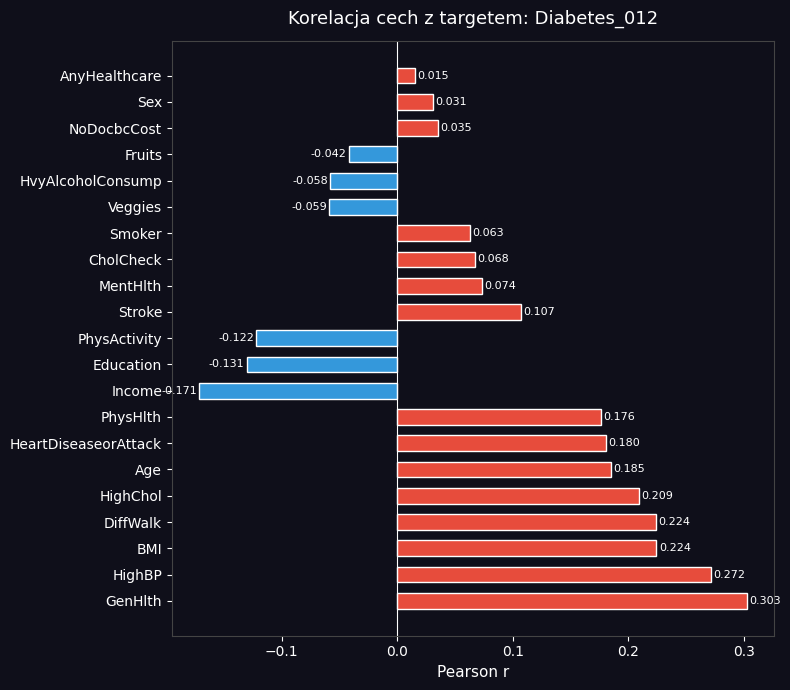

In [6]:
# --- Top korelacje z targetem ---
target = 'Diabetes_012'  # zmień na 'Diabetes_012' jeśli używasz tamtego pliku

target_corr = corr[target].drop(target).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
colors = ['#e74c3c' if v > 0 else '#3498db' for v in target_corr.values]

bars = ax.barh(target_corr.index, target_corr.values, color=colors, edgecolor='white', height=0.6)

ax.axvline(0, color='white', linewidth=0.8)
ax.set_xlabel('Pearson r', fontsize=11)
ax.set_title(f'Korelacja cech z targetem: {target}', fontsize=13, pad=12)
ax.set_facecolor('#0f0f1a')
fig.patch.set_facecolor('#0f0f1a')
ax.tick_params(colors='white')
ax.xaxis.label.set_color('white')
ax.title.set_color('white')
for spine in ax.spines.values():
    spine.set_edgecolor('#444')

# Wartości na słupkach
for bar, val in zip(bars, target_corr.values):
    ax.text(
        val + (0.002 if val >= 0 else -0.002),
        bar.get_y() + bar.get_height() / 2,
        f'{val:.3f}',
        va='center',
        ha='left' if val >= 0 else 'right',
        fontsize=8,
        color='white'
    )

plt.tight_layout()
plt.savefig('target_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# --- Pary cech o wysokiej wzajemnej korelacji (potencjalna redundancja) ---
threshold = 0.3

corr_upper = corr.where(mask == False)  # górny trójkąt bez diagonali
high_corr_pairs = (
    corr_upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'Feature_A', 'level_1': 'Feature_B', 0: 'r'})
)
high_corr_pairs = high_corr_pairs[high_corr_pairs['r'].abs() >= threshold]
high_corr_pairs = high_corr_pairs.sort_values('r', key=abs, ascending=False)

print(f'Pary cech z |r| >= {threshold}:')
print(high_corr_pairs.to_string(index=False))

Pary cech z |r| >= 0.3:
Feature_A    Feature_B         r
 PhysHlth      GenHlth  0.524364
 DiffWalk     PhysHlth  0.478417
 DiffWalk      GenHlth  0.456920
   Income    Education  0.449106
   Income      GenHlth -0.370014
 PhysHlth     MentHlth  0.353619
      Age       HighBP  0.344452
   Income     DiffWalk -0.320124
  GenHlth Diabetes_012  0.302587
 MentHlth      GenHlth  0.301674
  GenHlth       HighBP  0.300530
